# 1. A COSMIC population of white dwarf + main-sequence binaries

Stage 1 of the forward model. Draw zero-age binaries from the Moe & Di Stefano (2017)
correlated distributions, give them a constant star formation rate over 10 Gyr, evolve
them with COSMIC (BSE), and keep the systems that are a **detached WD + MS pair today**.

```
[COSMIC population]  ->  Galaxy placement  ->  Gaia selection  ->  compare to DR3 / DR4
```

The science question this stage sets up: Gaia DR3 found about 3,200 WD + MS astrometric
binaries at P = 100-1000 d (Shahaf et al. 2024). Standard binary evolution predicts
that range should be nearly empty, because common envelope evolution shrinks orbits to
days and stable mass transfer leaves them wider. How a model fills that window is a
direct test of common envelope and AGB mass-transfer physics.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

In [2]:
from popsynth import population, analysis
from popsynth.bse_defaults import default_bse_dict

## A small run from scratch

`population.build` runs all of stage 1. A few thousand zero-age binaries take about
20 seconds on two cores. The returned table is oriented as MS / WD whichever star became
the white dwarf, and carries the total stellar mass formed, which is needed later for
absolute counts.

In [3]:
demo = population.build(3000, seed=42, nproc=2)
print(f"{len(demo)} present-day WD+MS systems from 3000 zero-age binaries")
print(f"stellar mass formed to make them: {demo.attrs['mass_formed']:.3g} Msun")
demo[["m_ms", "m_wd", "porb", "ecc", "t_cool", "age", "porb_zams", "had_ce"]].head()

476 present-day WD+MS systems from 3000 zero-age binaries
stellar mass formed to make them: 2e+04 Msun


,m_ms,m_wd,porb,ecc,t_cool,age,porb_zams,had_ce
bin_num,,,,,,,,
4,1.403872,0.613365,2.865008e+04,0.439889,190.845899,2072.067605,14714.515753,False
7,1.027631,0.773654,2.703388e+00,0.000000,9199.360282,9501.561471,882.907831,True
12,0.464805,0.569372,6.061043e-01,0.000000,2176.637368,3108.474110,207.390343,True
18,0.244730,0.602776,1.752867e+06,0.454177,5281.494044,8082.919581,402028.514000,False
28,0.856776,1.031631,2.861288e+06,0.520956,7666.106047,7715.248481,106770.896630,False


The physics knobs are COSMIC's BSE flags. The defaults come from COSMIC's own
settings file; anything can be overridden by keyword, e.g. `population.build(..., alpha1=[5.0, 5.0])`.

In [4]:
bse = default_bse_dict()
{k: bse[k] for k in ["alpha1", "lambdaf", "qcflag", "kickflag", "wdflag", "ifflag"]}

{'alpha1': [1.0, 1.0],
 'lambdaf': 0.0,
 'qcflag': 5,
 'kickflag': 5,
 'wdflag': 1,
 'ifflag': 1}

## The cached production populations

Two variants were run from **the same 60,000 zero-age binaries** (seed 11), differing
only in common envelope efficiency:

| tag | alpha1 | meaning |
| --- | --- | --- |
| `fiducial` | 1.0 | COSMIC default |
| `alpha5` | 5.0 | very efficient envelope ejection |

Regenerate with `python scripts/run_population.py --tag alpha5 --alpha 5.0 --n 60000 --seed 11` (about 3 minutes each).

In [5]:
pops = {t: analysis.load_population(t) for t in ["fiducial", "alpha5"]}
pd.DataFrame({
    t: {
        "WD+MS systems": len(p),
        "fraction with P = 100-1000 d": ((p.porb > 100) & (p.porb < 1000)).mean(),
        "fraction that went through CE": p.had_ce.mean(),
        "median WD mass [Msun]": p.m_wd.median(),
    } for t, p in pops.items()
}).round(3)

,fiducial,alpha5
WD+MS systems,9575.000,10657.000
fraction with P = 100-1000 d,0.007,0.047
fraction that went through CE,0.291,0.359
median WD mass [Msun],0.614,0.611


## Where the orbits end up

Each point is a present-day WD + MS binary: its zero-age period against today's period.
Systems that went through a common envelope (red) drop by orders of magnitude; systems
that never interacted (grey) move up slightly as the WD progenitor loses mass. The grey
band is Gaia DR3's astrometric window.

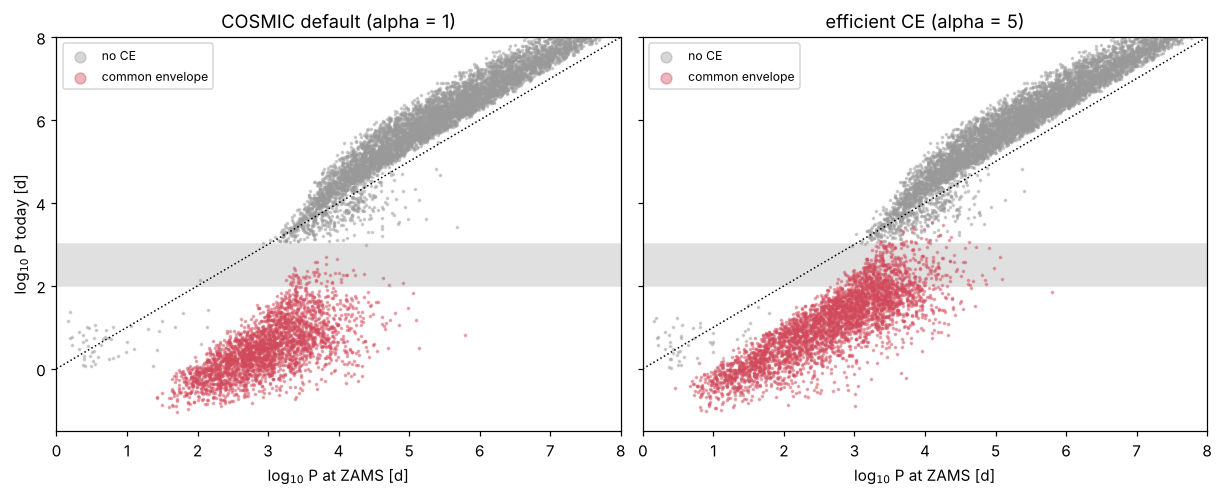

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, constrained_layout=True)
for ax, (t, p) in zip(axes, pops.items()):
    for ce, c, lab in [(False, "0.6", "no CE"), (True, "#d1495b", "common envelope")]:
        s = p[p.had_ce == ce]
        ax.scatter(np.log10(s.porb_zams), np.log10(s.porb), s=2, alpha=0.4, color=c, label=lab, rasterized=True)
    ax.axhspan(2, 3, color="0.88", zorder=0)
    ax.plot([0, 8], [0, 8], "k:", lw=1)
    ax.set_xlim(0, 8); ax.set_ylim(-1.5, 8)
    ax.set_xlabel("log$_{10}$ P at ZAMS [d]")
    ax.set_title(analysis.LABELS[t])
    ax.legend(markerscale=5, fontsize=8, loc="upper left")
axes[0].set_ylabel("log$_{10}$ P today [d]")
plt.show()

With alpha = 1, almost nothing lands in the grey band: the CE products are too tight and
the non-interacting systems too wide. Raising alpha to 5 lets CE survivors stay wider and
partly fills the window. Whether that matches Gaia's period *distribution*, and not just
its occupancy, is the question for notebook 3.

## What happened to everything else

WD + MS pairs are only about a sixth of the 60,000 zero-age binaries. `data/final_<tag>.csv.gz`
keeps the final state of **every** binary, classified by `population.classify_final`:

| state | meaning |
| --- | --- |
| `ms_ms` | both stars still on the main sequence |
| `wd_ms` | detached WD + MS (the Gaia sample above) |
| `merged` | coalesced, mostly during common envelope |
| `wd_wd` | detached double white dwarf |
| `disrupted` | unbound, e.g. by a supernova kick |
| `wd_other` | WD with a giant, subgiant or helium star |
| `no_wd_other` | no WD yet: mostly a giant or subgiant with an MS companion |
| `interacting` | bound, one star filling its Roche lobe today |
| `wd_co` | WD with a neutron star or black hole |

In [7]:
finals = {t: analysis.load_final(t) for t in ["fiducial", "alpha5"]}
order = ["ms_ms", "wd_ms", "merged", "wd_wd", "disrupted", "wd_other", "no_wd_other", "interacting", "wd_co"]
counts = pd.DataFrame({t: f.final_state.value_counts() for t, f in finals.items()}).reindex(order).fillna(0).astype(int)
share = (100 * counts / counts.sum()).round(1).add_suffix(" %")
pd.concat([counts, share], axis=1)

,fiducial,alpha5,fiducial %,alpha5 %
final_state,,,,
ms_ms,36128,36126,60.2,60.2
wd_ms,9575,10657,16.0,17.8
merged,7589,4435,12.6,7.4
wd_wd,2901,5292,4.8,8.8
disrupted,1438,1503,2.4,2.5
wd_other,1041,684,1.7,1.1
no_wd_other,1046,1102,1.7,1.8
interacting,259,151,0.4,0.3
wd_co,23,50,0.0,0.1


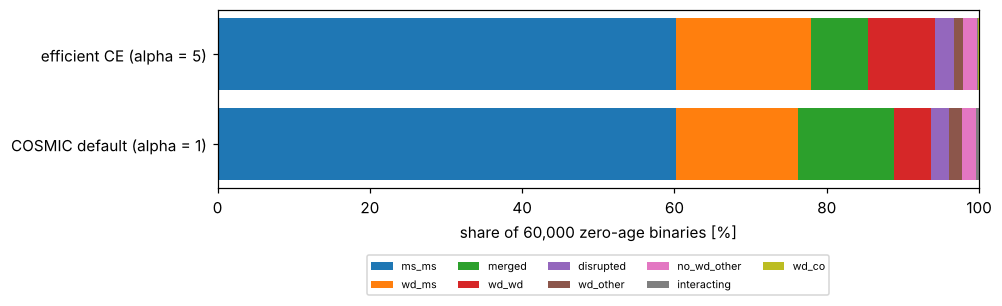

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.6), constrained_layout=True)
cmap = plt.get_cmap("tab10")
for row, (t, f) in enumerate(finals.items()):
    left = 0
    for i, st in enumerate(order):
        w = 100 * (f.final_state == st).mean()
        ax.barh(row, w, left=left, color=cmap(i), label=st if row == 0 else None)
        left += w
ax.set_yticks([0, 1], [analysis.LABELS[t] for t in finals])
ax.set_xlabel("share of 60,000 zero-age binaries [%]"); ax.set_xlim(0, 100)
ax.legend(ncol=5, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.35))
plt.show()

Same zero-age binaries, so differences are pure physics. Efficient envelope ejection turns
mergers into survivors: the merged share falls and both the WD + MS and the double white dwarf
shares rise.

### Double white dwarfs, for the Type Ia thread

The `wd_wd` systems are the population behind double-degenerate Type Ia rates and the LISA
foreground. Their period distribution shows the same physics split as WD + MS: wide pairs that never
interacted, and tight post-common-envelope pairs. Only the tight ones can merge within a Hubble time
by gravitational-wave emission.

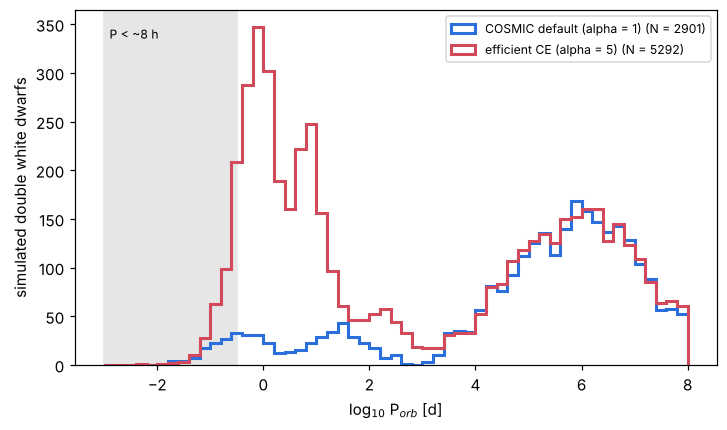

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.8), constrained_layout=True)
bins = np.linspace(-3, 8, 56)
for t, f in finals.items():
    w = f[f.final_state == "wd_wd"]
    ax.hist(np.log10(w.porb), bins=bins, histtype="step", lw=2, color=analysis.COLORS[t],
            label=f"{analysis.LABELS[t]} (N = {len(w)})")
ax.set_xlabel("log$_{10}$ P$_{orb}$ [d]"); ax.set_ylabel("simulated double white dwarfs")
ax.axvspan(-3, -0.5, color="0.9", zorder=0)
ax.text(-2.9, ax.get_ylim()[1] * 0.92, "P < ~8 h", fontsize=8)
ax.legend(fontsize=8)
plt.show()

In [10]:
pd.DataFrame({
    t: {
        "double WDs": int((f.final_state == "wd_wd").sum()),
        "with P < 1 d": int(((f.final_state == "wd_wd") & (f.porb < 1)).sum()),
        "merged systems that went through CE": round(f[f.final_state == "merged"].had_ce.mean(), 2),
    } for t, f in finals.items()
})

,fiducial,alpha5
double WDs,2901.00,5292.00
with P < 1 d,177.00,1048.00
merged systems that went through CE,0.93,0.88


A double-white-dwarf analysis would extend these tables with WD compositions (He vs CO, from the
kstar codes) and gravitational-wave merger times. That's what's needed to split the predicted Type Ia
delay-time distribution into CO + CO and CO + He channels.

Next: [02_galaxy_and_gaia_selection.ipynb](02_galaxy_and_gaia_selection.ipynb).